## SIS -- 2
### Myrzakassymov Azizkhan
### September 2026


### Additional Information

The data is related with direct marketing campaigns of a Portuguese banking institution. The marketing campaigns were based on phone calls. Often, more than one contact to the same client was required, in order to access if the product (bank term deposit) would be ('yes') or not ('no') subscribed. 

### Input variables:
   #### bank client data:
   1. age (numeric)
   2. job : type of job (categorical: "admin.","blue-collar","entrepreneur","housemaid","management","retired","self-employed","services","student","technician","unemployed","unknown")
   3. marital : marital status (categorical: "divorced","married","single","unknown"; note: "divorced" means divorced or widowed)
   4. education (categorical: "basic.4y","basic.6y","basic.9y","high.school","illiterate","professional.course","university.degree","unknown")
   5. default: has credit in default? (categorical: "no","yes","unknown")
   6. housing: has housing loan? (categorical: "no","yes","unknown")
   7. loan: has personal loan? (categorical: "no","yes","unknown")
   #### related with the last contact of the current campaign:
   8. contact: contact communication type (categorical: "cellular","telephone") 
   9. month: last contact month of year (categorical: "jan", "feb", "mar", ..., "nov", "dec")
  10. day_of_week: last contact day of the week (categorical: "mon","tue","wed","thu","fri")
  11. duration: last contact duration, in seconds (numeric). Important note:  this attribute highly affects the output target (e.g., if duration=0 then y="no"). Yet, the duration is not known before a call is performed. Also, after the end of the call y is obviously known. Thus, this input should only be included for benchmark purposes and should be discarded if the intention is to have a realistic predictive model.
   #### other attributes:
  12. campaign: number of contacts performed during this campaign and for this client (numeric, includes last contact)
  13. pdays: number of days that passed by after the client was last contacted from a previous campaign (numeric; 999 means client was not previously contacted)
  14. previous: number of contacts performed before this campaign and for this client (numeric)
  15. poutcome: outcome of the previous marketing campaign (categorical: "failure","nonexistent","success")
   #### social and economic context attributes
  16. emp.var.rate: employment variation rate - quarterly indicator (numeric)
  17. cons.price.idx: consumer price index - monthly indicator (numeric)     
  18. cons.conf.idx: consumer confidence index - monthly indicator (numeric)     
  19. euribor3m: euribor 3 month rate - daily indicator (numeric)
  20. nr.employed: number of employees - quarterly indicator (numeric)

## Task 1. 
Perform FULL and comprehensive EDA (check imbalance, visualize key features vs
target, correlation heatmap). Describe the dataset (rows, features, target). Show
class distribution (plot required)

In [1]:
import numpy as np 
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import xgboost as xgb

import sklearn.compose as compose
import sklearn.preprocessing as preprocessing

In [2]:
df = pd.read_csv('bank-additional-full.csv', sep=';')

pd.set_option('display.max_columns', None)

display(df)

,age,job,marital,education,default,housing,loan,contact,month,day_of_week,duration,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
0,56,housemaid,married,basic.4y,no,no,no,telephone,may,mon,261,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
1,57,services,married,high.school,unknown,no,no,telephone,may,mon,149,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
2,37,services,married,high.school,no,yes,no,telephone,may,mon,226,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
3,40,admin.,married,basic.6y,no,no,no,telephone,may,mon,151,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
4,56,services,married,high.school,no,no,yes,telephone,may,mon,307,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
41183,73,retired,married,professional.course,no,yes,no,cellular,nov,fri,334,1,999,0,nonexistent,-1.1,94.767,-50.8,1.028,4963.6,yes
41184,46,blue-collar,married,professional.course,no,no,no,cellular,nov,fri,383,1,999,0,nonexistent,-1.1,94.767,-50.8,1.028,4963.6,no
41185,56,retired,married,university.degree,no,yes,no,cellular,nov,fri,189,2,999,0,nonexistent,-1.1,94.767,-50.8,1.028,4963.6,no
41186,44,technician,married,professional.course,no,no,no,cellular,nov,fri,442,1,999,0,nonexistent,-1.1,94.767,-50.8,1.028,4963.6,yes


In [3]:
# Cheking class imbalance

target_imbalance = len(df[df['y'] == 'yes']['y'])/len(df) # percentage of class "yes" in target
print(f'Percentage of class "yes" in target {round(target_imbalance * 100, 2)}%')

Percentage of class "yes" in target 11.27%


In [4]:
# checking null values
display(df.isna().sum())

age               0
job               0
marital           0
education         0
default           0
housing           0
loan              0
contact           0
month             0
day_of_week       0
duration          0
campaign          0
pdays             0
previous          0
poutcome          0
emp.var.rate      0
cons.price.idx    0
cons.conf.idx     0
euribor3m         0
nr.employed       0
y                 0
dtype: int64

We can see that there's no missing values in dataset, though, there is values 'Unknown'.


,corr
nr.employed,-0.354678
pdays,-0.324914
euribor3m,-0.307771
emp.var.rate,-0.298334
cons.price.idx,-0.136211
campaign,-0.066357
age,0.030399
cons.conf.idx,0.054878
previous,0.230181
duration,0.405274


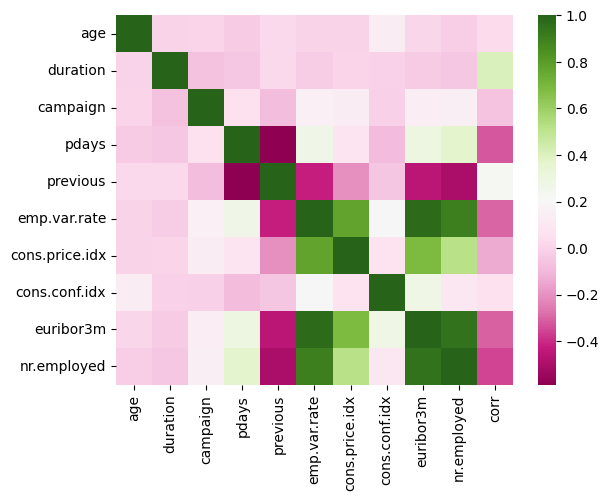

In [5]:
num = df.select_dtypes('number').columns.to_list()
target = (df['y'] == 'yes').astype(int)

corr = df[num].corrwith(target).to_frame('corr')
display(corr.sort_values(by='corr'))

corr_gen = pd.concat([df[num].corr(), corr], axis=1)
fig = plt.plot()
sns.heatmap(data=corr_gen, cmap='PiYG') 
plt.show()

We can see that most of numerical features HAS correlations between classes "Yes" or "No" in target variable.

I decided to divide categorical and numerical plots in "Target vs Features", to avoid confusion.

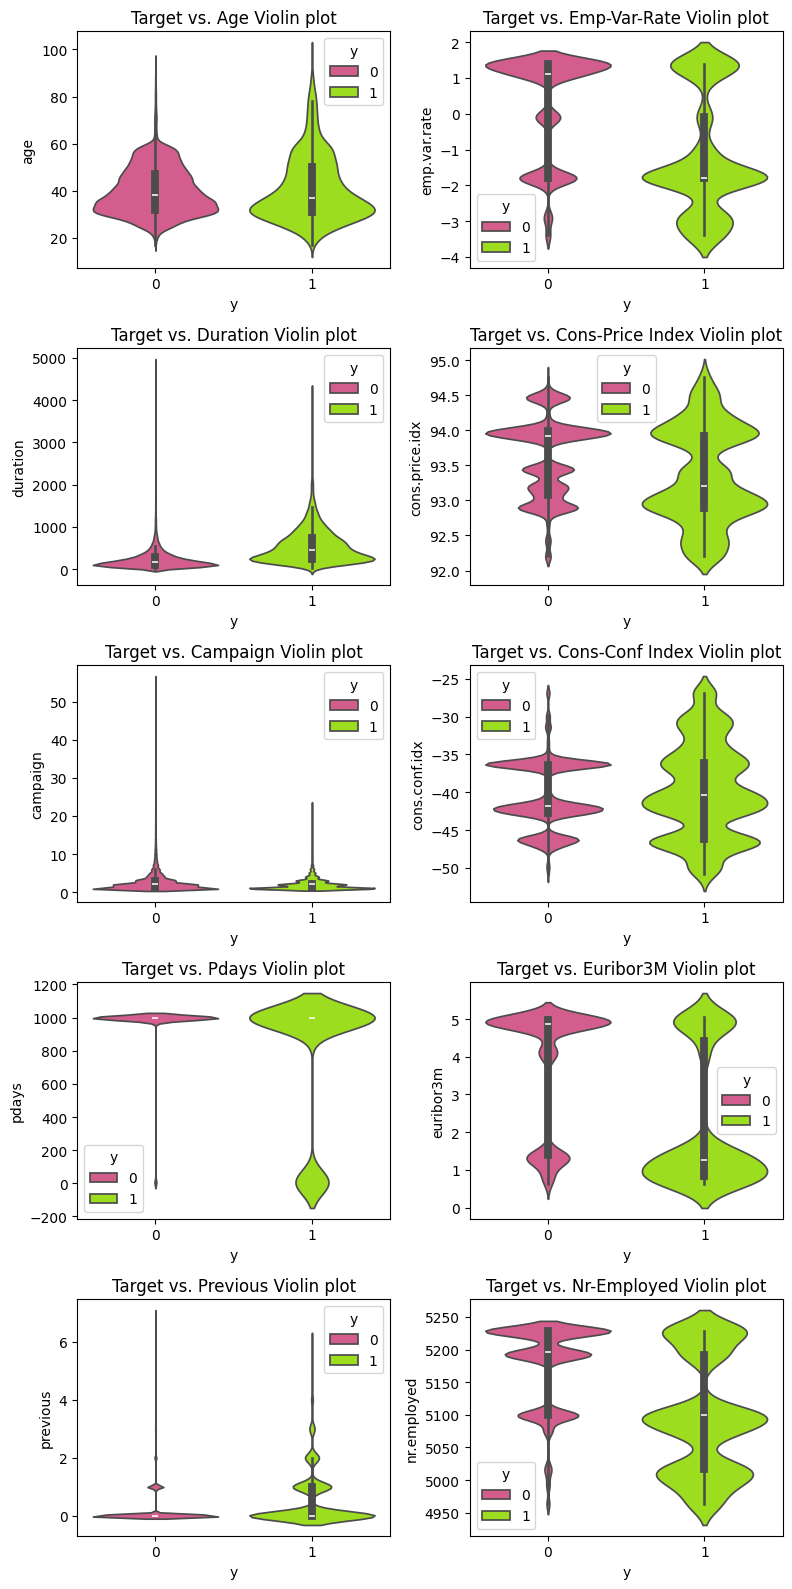

In [6]:
# For numerical categories
fig, ax = plt.subplots(figsize=(8, 16), nrows=5, ncols=2, dpi=100)
ax = ax.flatten(order='F')

for i, idx in enumerate(num):
    title = (
        idx.replace('_', ' ').
        replace('.', '-').
        replace('-idx', ' Index').
        replace('poutcome', 'p-Outcome').
        title()
    )
    title = 'Target vs. ' + title + ' Violin plot'
    sns.violinplot( 
        ax=ax[i],
        y=df[idx],
        x=target,
        hue=target,
        palette=["#e64b8b", '#a7fc00']
    )
    ax[i].set_title(title)

plt.tight_layout()
plt.show()

We can see that in there is a lot of features where we can see some extraordinal difference between 0 (no) and 1 (yes), for example Target vs Cons-Price Index; Cons-Price Index stands for Consumer-Price index for this month. Most difference comes between 92-93.5 percents.

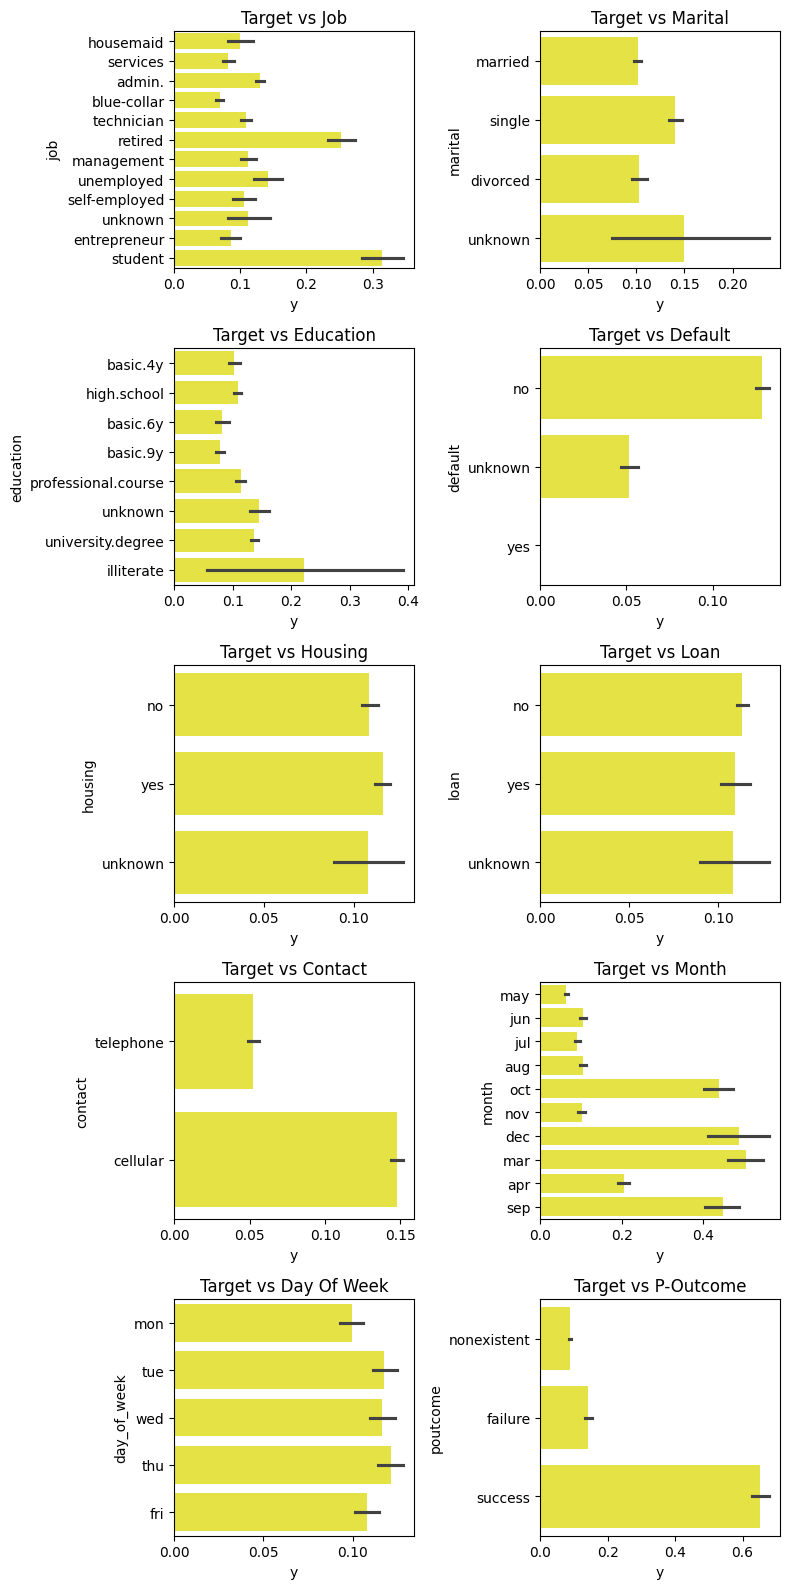

In [ ]:
# Target vs Feature plots for categorical distributions
features = df.select_dtypes('object').drop('y', axis=1, inplace=False)
cat = df.select_dtypes('object').drop('y', axis=1, inplace=False).columns.to_list()

fig, ax = plt.subplots(figsize=(8, 16), nrows=5, ncols=2, dpi=100)
ax = ax.flatten()
for i, idx in enumerate(cat):
    title = (
        idx.replace('_', ' ').
        replace('.', '-').
        replace('-idx', ' Index').
        replace('poutcome', 'p-Outcome').
        title()
    )
    title = 'Target vs ' + title 

    sns.barplot( 
        ax=ax[i],
        y=df[idx],
        x=target,
        color="#FFFB2C"
    )
    ax[i].set_title(title)


plt.tight_layout()
plt.show()


As we can see, students and retired people have the biggest average result (0.3 and ~0.25 respectfully) in getting term deposit.

Also success of Previous outcome (P-outcome) is a very good indicator to get term deposit.

Cellular contact also has 15% of positive class, with 95% confidence interval somewhere around. 

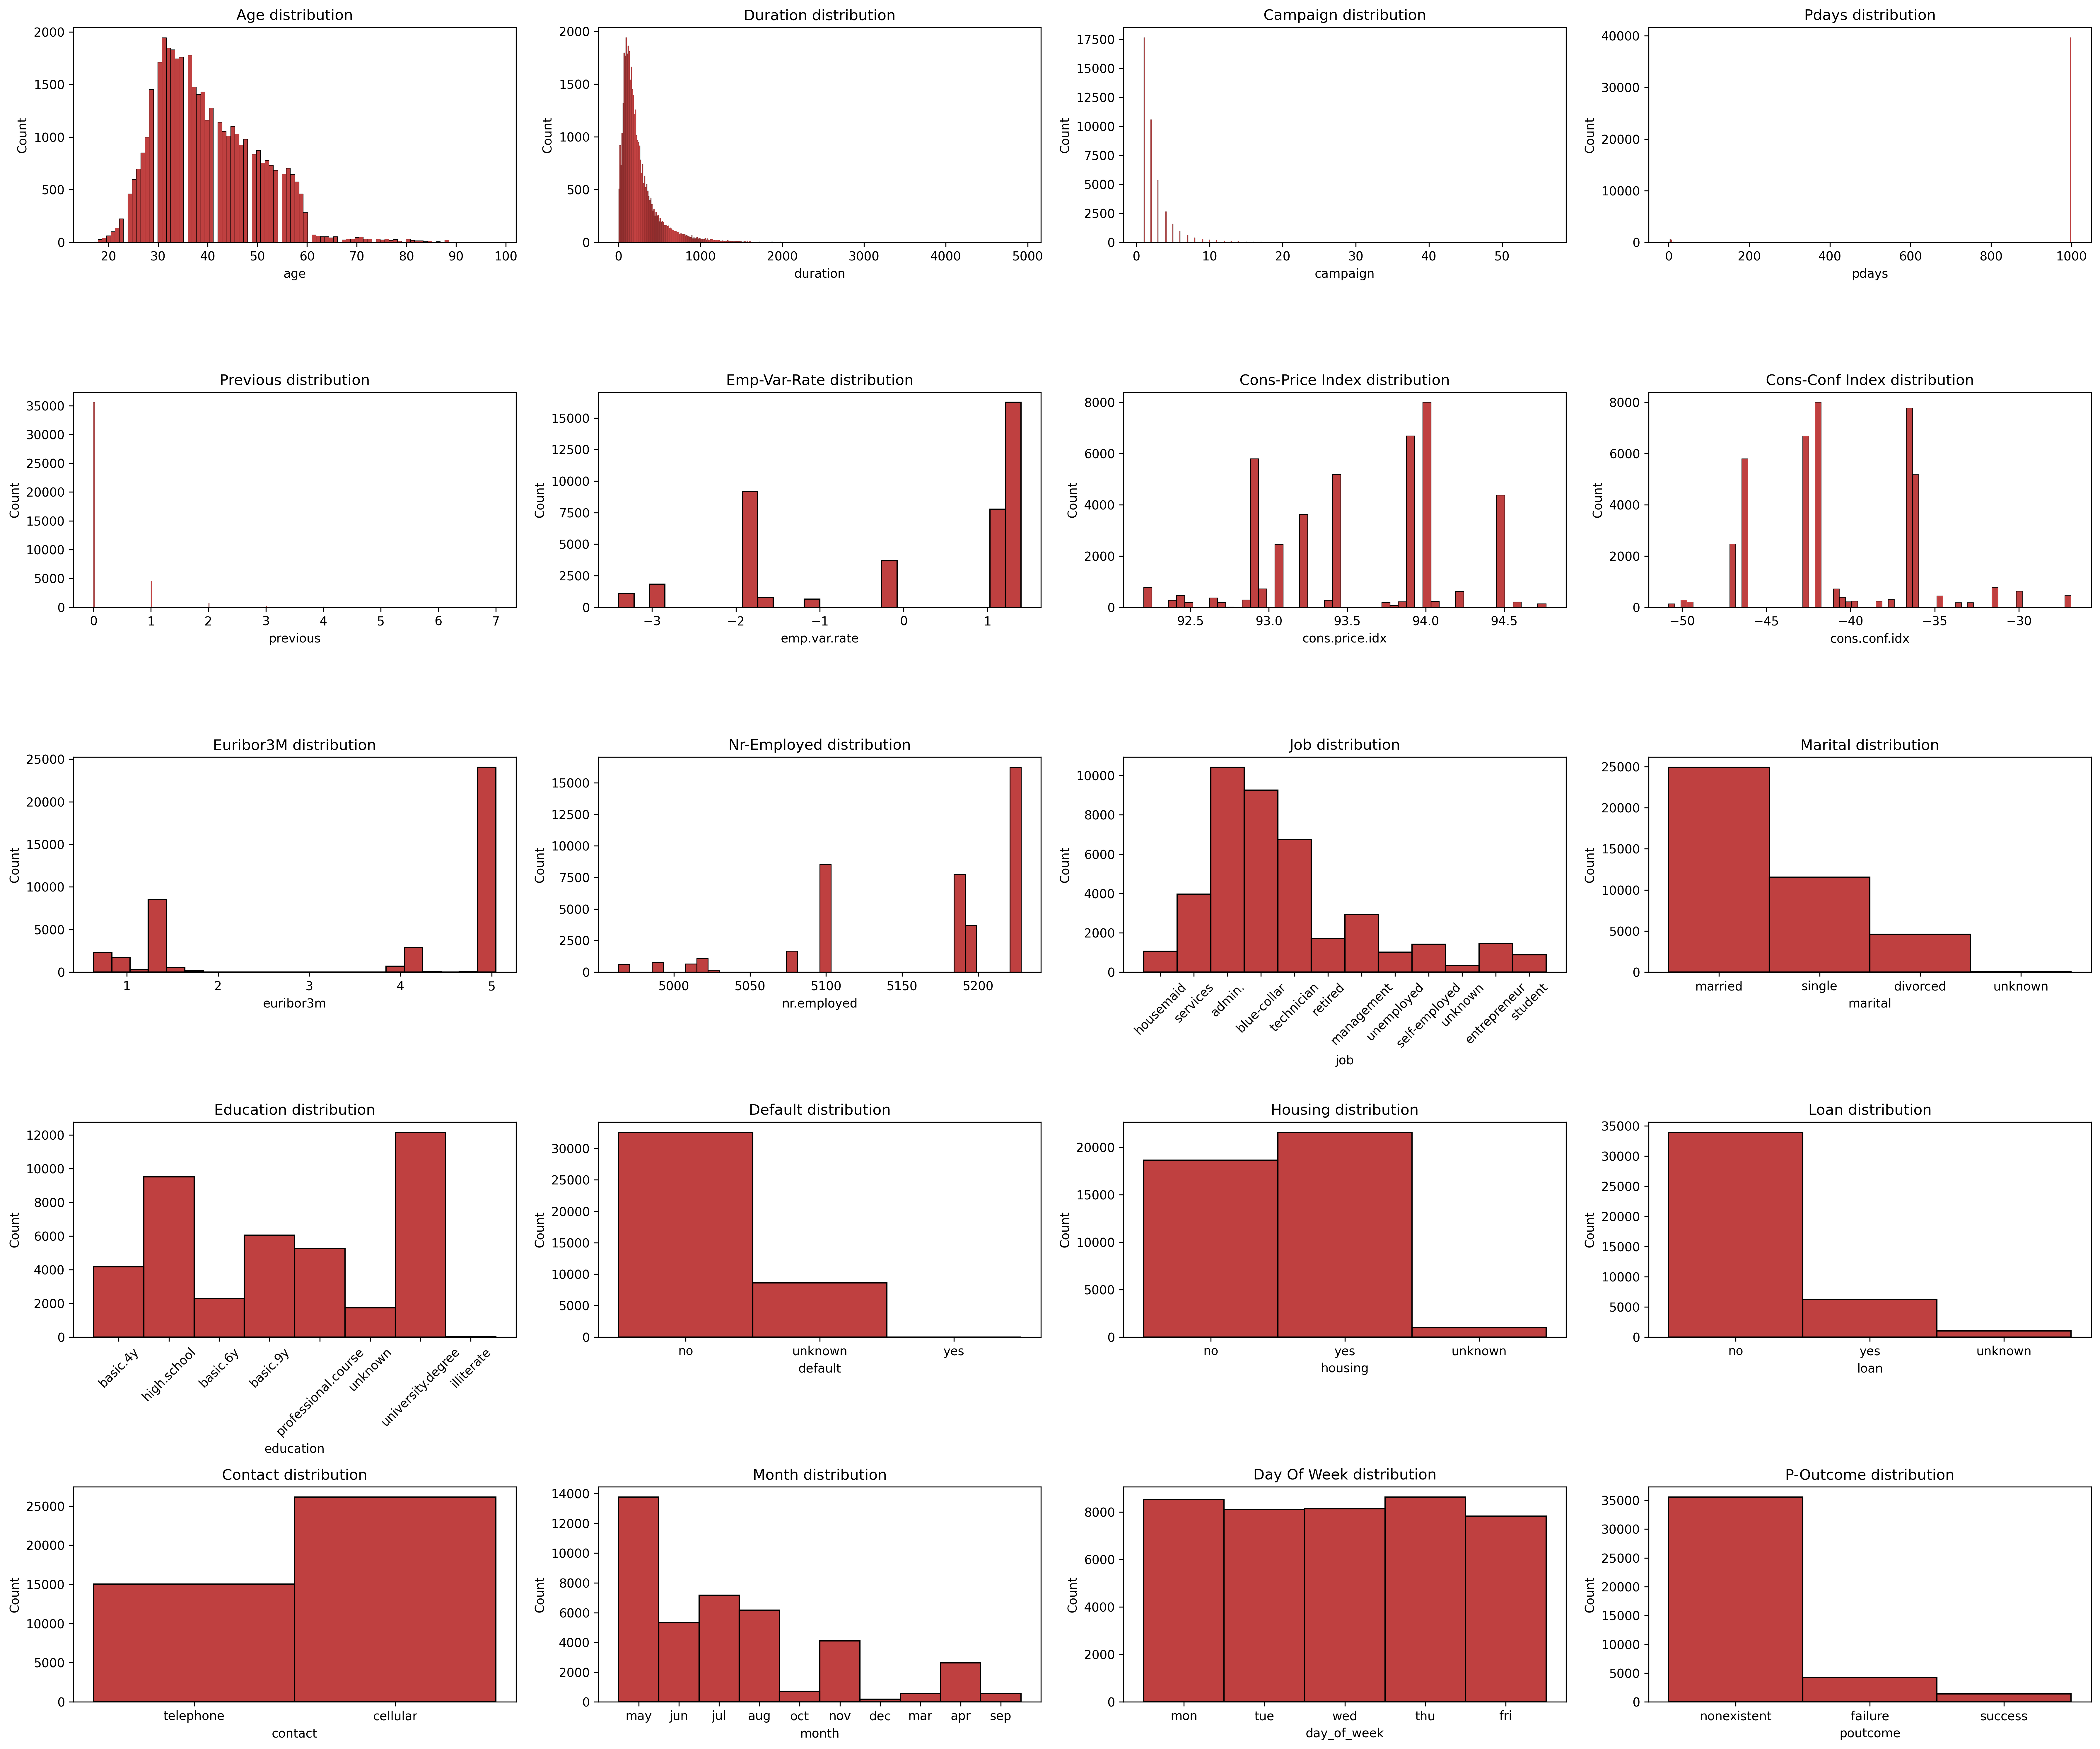

In [8]:
# Visualizing data distribution
fig, ax = plt.subplots(figsize=(24, 20), nrows=5, ncols=4, dpi=300)
ax = ax.flatten()

for i, idx in enumerate((num) + (cat)):
    title = (
        idx.replace('_', ' ').
        replace('.', '-').
        replace('-idx', ' Index').
        replace('poutcome', 'p-Outcome').
        title()
    )
    title = title + ' distribution'
    sns.histplot(
        ax=ax[i],
        data=df[idx],
        color="#AA0000"
    )
    ax[i].set_title(title)

ax[10].tick_params(axis='x', rotation=45)
ax[12].tick_params(axis='x', rotation=45)
plt.tight_layout()
plt.show()

We can clearly see which feature has associate link between target and which is not. Accuracy may strongly depend on features that we will select.

2. Preprocess data (try to capture all tools from lecture material)

In [9]:
from sklearn.model_selection import train_test_split
from sklearn.utils import column_or_1d

In [112]:
# Data preprocessing
num = (
    df.select_dtypes('number').
    columns.
    to_list()
)
cat = (
    df.select_dtypes('object').
    drop('y', axis=1, inplace=False).
    columns.
    to_list()
)

# Preprocessor 
preprocessor = compose.ColumnTransformer(
    transformers=[
        ('num', preprocessing.StandardScaler(), num),
        ('cat', preprocessing.OneHotEncoder(), cat),
    ]
)

X = df[num + cat] # features
y = (df['y'] == 'yes') # target, yes is positive class

X_train, X_test, y_train, y_test = train_test_split(X, column_or_1d(y, warn=False), test_size=0.2) # splitting data

3. Train models (Logistic Regression, Decision Tree/ Random Forest,
XGBoost/LightGBM, KNN, SVM)


In [11]:
from sklearn.pipeline import Pipeline

Let's start with Feature selection, it is a code that uses Cross Validation to obtain results.

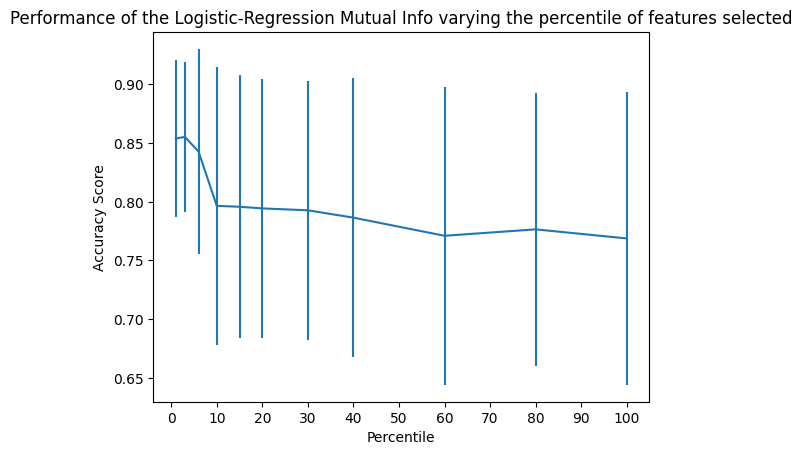

In [100]:
from sklearn.linear_model import LogisticRegression
from sklearn.feature_selection import SelectPercentile, mutual_info_classif
from sklearn.model_selection import cross_val_score

# Logistic Regression
lr_pipeline = Pipeline([
        ('preprocessor', preprocessor),
        ('selection_cat', SelectPercentile(mutual_info_classif)),
        ('classifier', LogisticRegression())
    ]
)

score_means = list()
score_stds = list()
k = (1, 3, 6, 10, 15, 20, 30, 40, 60, 80, 100)

features = df[num + cat]
targets = df['y']

for percentile in k:
    lr_pipeline.set_params(selection_cat__percentile=percentile)
    this_scores = cross_val_score(lr_pipeline, features, targets)
    score_means.append(this_scores.mean())
    score_stds.append(this_scores.std())

plt.errorbar(k, score_means, np.array(score_stds))
plt.title("Performance of the Logistic-Regression Mutual Info varying the percentile of features selected")
plt.xticks(np.linspace(0, 100, 11, endpoint=True))
plt.xlabel("Percentile")
plt.ylabel("Accuracy Score")
plt.axis("tight")
plt.show()

Code needed 10 minutes to render, but here it is, we can very clearly see that we SHOULD use feature selection.

With this result I will use 6 percents of features. I assume that all models should perform somewhat equally because of mutual information between X and y.

In [113]:
from sklearn.linear_model import LogisticRegression

# Logistic Regression
lr_pipeline = Pipeline([
        ('preprocessor', preprocessor),
        ('selection', SelectPercentile(mutual_info_classif, percentile=6)),
        ('classifier', LogisticRegression())
    ]
)

lr_pipeline.fit(X_train, y_train)

,steps,"[('preprocessor', ...), ('selection', ...), ...]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('num', ...), ('cat', ...)]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


In [114]:
from sklearn.ensemble import RandomForestClassifier

# Random Forest
rf_pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('selection', SelectPercentile(mutual_info_classif, percentile=6)),
    ('classifier', RandomForestClassifier(criterion='entropy'))
    ]
)

rf_pipeline.fit(X_train, y_train)

,steps,"[('preprocessor', ...), ('selection', ...), ...]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('num', ...), ('cat', ...)]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


In [115]:
# XGBoost

xgb_pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('selection', SelectPercentile(mutual_info_classif, percentile=6)),
    ('classifier', xgb.XGBClassifier())
    ]
)


xgb_pipeline.fit(X_train, y_train)


,steps,"[('preprocessor', ...), ('selection', ...), ...]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('num', ...), ('cat', ...)]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


In [116]:
from sklearn.neighbors import KNeighborsClassifier

# KNN
k=9

knn_pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('selection', SelectPercentile(mutual_info_classif, percentile=6)),
    ('classifier', KNeighborsClassifier(n_neighbors=k))
    ]
)

knn_pipeline.fit(X_train, y_train)

,steps,"[('preprocessor', ...), ('selection', ...), ...]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('num', ...), ('cat', ...)]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


In [117]:
from sklearn.svm import SVC
# SVM

svc_pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('selection', SelectPercentile(mutual_info_classif, percentile=6)),
    ('classifier', SVC(kernel='rbf', probability=True))
    ]
)

svc_pipeline.fit(X_train, y_train)

,steps,"[('preprocessor', ...), ('selection', ...), ...]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('num', ...), ('cat', ...)]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


4. Evaluate using ROC-AUC, PR-AUC, F1, Precision, Recall, Confusion Matrix,
Show ROC-AUC, PR-AUC Curves

In [17]:
import sklearn.metrics as metrics

In [118]:
pipes = {
    'Logistic Regression' : lr_pipeline,
    'Random Forest' : rf_pipeline,
    'XGBoost' : xgb_pipeline,
    'KNN' : knn_pipeline,
    'Support Vector Machine' : svc_pipeline
}

for pipe in pipes:
    y_pred = pipes[pipe].predict(X_test)

    roc_auc = metrics.roc_auc_score(y_test, y_pred)
    accuracy = metrics.accuracy_score(y_test, y_pred)
    f1 = metrics.f1_score(y_test, y_pred)
    precision = metrics.precision_score(y_test, y_pred)
    recall = metrics.recall_score(y_test, y_pred)

    print(f'For {pipe}: \nAccuracy: {accuracy}\nF1-score: {f1}\nPrecision: {precision}\nRecall: {recall}\nROC-AUC: {roc_auc}\n')

For Logistic Regression: 
Accuracy: 0.9119932022335518
F1-score: 0.463360473723168
Precision: 0.6716738197424893
Recall: 0.3536723163841808
ROC-AUC: 0.6664322414234245

For Random Forest: 
Accuracy: 0.902282107307599
F1-score: 0.5261918775750442
Precision: 0.5491400491400491
Recall: 0.5050847457627119
ROC-AUC: 0.7275865725277587

For XGBoost: 
Accuracy: 0.9129643117261471
F1-score: 0.5667673716012085
Precision: 0.6090909090909091
Recall: 0.5299435028248588
ROC-AUC: 0.7445039151551195

For KNN: 
Accuracy: 0.9129643117261471
F1-score: 0.5587692307692308
Precision: 0.6135135135135135
Recall: 0.5129943502824859
ROC-AUC: 0.7370493307239983

For Support Vector Machine: 
Accuracy: 0.9146637533381888
F1-score: 0.5265993265993266
Precision: 0.6516666666666666
Recall: 0.44180790960451977
ROC-AUC: 0.7066920684973503



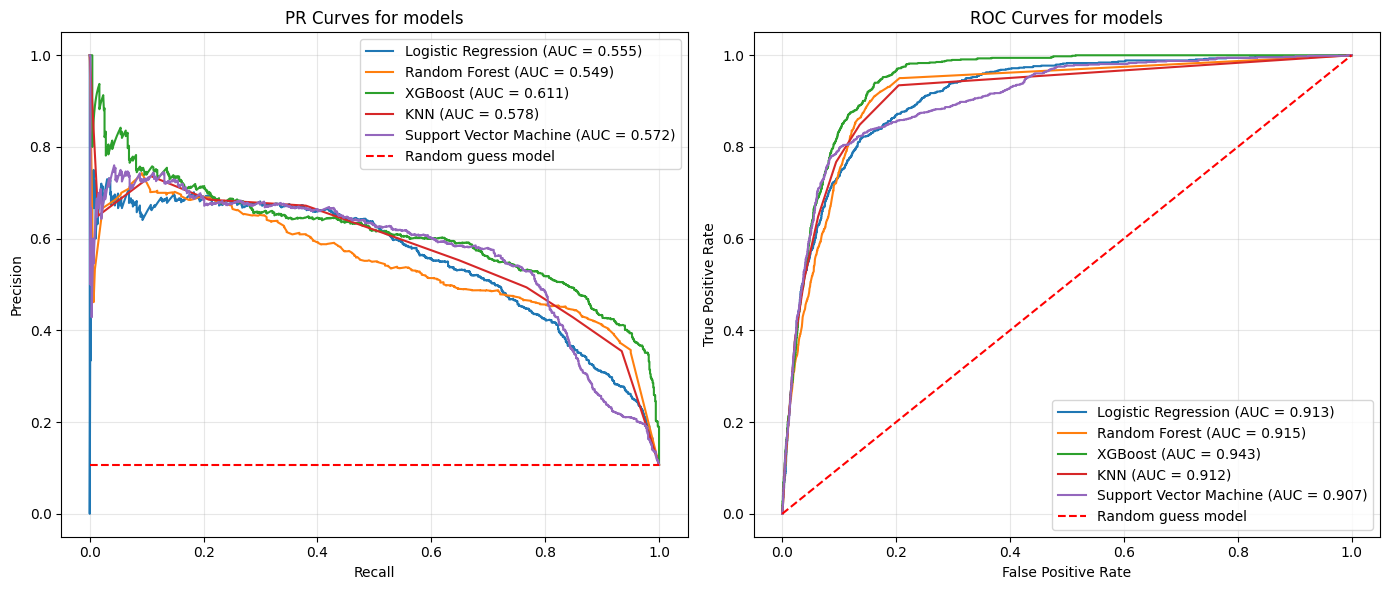

In [120]:
# ROC-AUC and PR-AUC curves

fig, ax = plt.subplots(ncols=2, figsize=(14, 6), dpi=100)

for pipe in pipes:
    y_proba = pipes[pipe].predict_proba(X_test)[:, 1]
    precision_, recall_, thresholds = metrics.precision_recall_curve(y_test, y_proba)
    auc = metrics.auc(recall_, precision_)
    ax[0].plot(recall_, precision_, label=f'{pipe} (AUC = {auc:.3f})')

for pipe in pipes:
    y_proba = pipes[pipe].predict_proba(X_test)[:, 1]
    fpr, tpr, _ = metrics.roc_curve(y_test, y_proba)
    auc = metrics.auc(fpr, tpr)
    ax[1].plot(fpr, tpr, label=f'{pipe} (AUC = {auc:.3f})')

# PR-curve
p_class = sum(y_test)/len(y_test)
ax[0].plot([0, 1], [p_class, p_class], 'r--', label='Random guess model')
ax[0].set_xlabel('Recall')
ax[0].set_ylabel('Precision')
ax[0].set_title('PR Curves for models')
ax[0].grid(True, alpha=0.3)
ax[0].legend()

# ROC
ax[1].plot([0, 1], [0, 1], 'r--', label='Random guess model')
ax[1].set_xlabel('False Positive Rate')
ax[1].set_ylabel('True Positive Rate')
ax[1].set_title('ROC Curves for models')
ax[1].grid(True, alpha=0.3)
ax[1].legend()

plt.tight_layout()
plt.show()

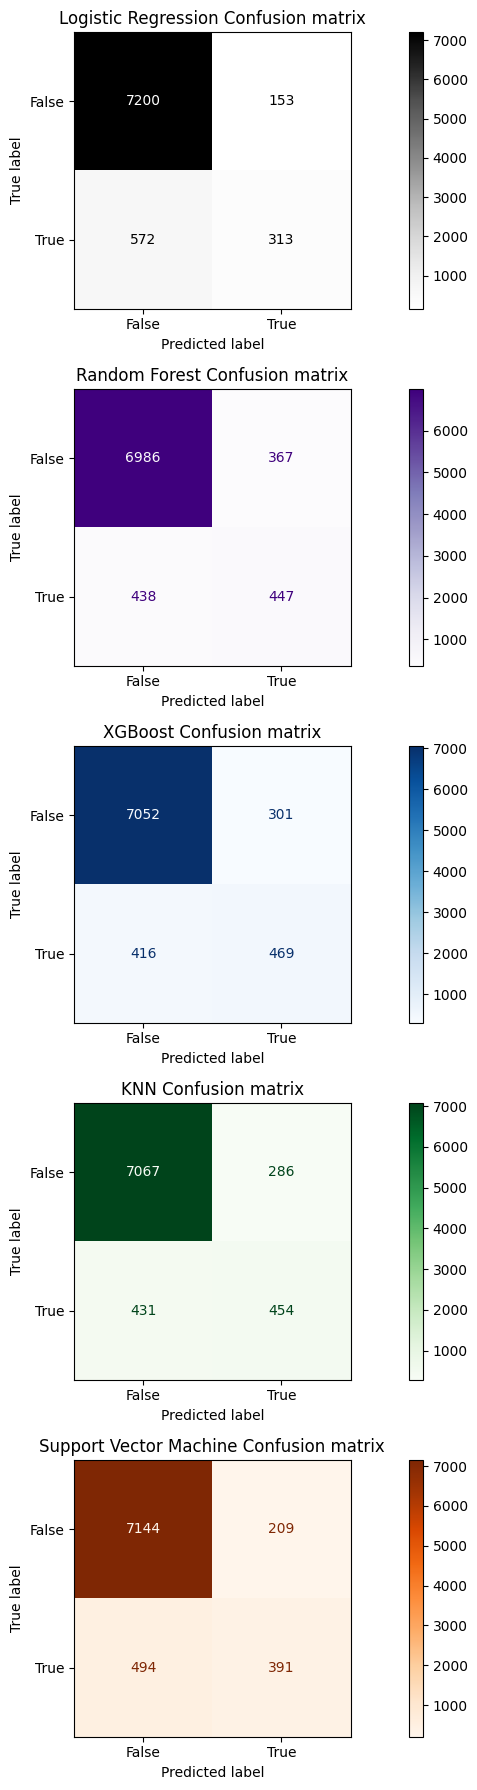

In [121]:
# Confusion Matrices
fig, ax = plt.subplots(nrows=5, figsize=(12, 18), dpi=100)
cmaps=['Greys', 'Purples', 'Blues', 'Greens', 'Oranges']

for i, pipe in enumerate(pipes):
    title = pipe + ' Confusion matrix'
    metrics.ConfusionMatrixDisplay.from_estimator(
        pipes[pipe],
        X_test,
        y_test,
        ax=ax[i],
        cmap=cmaps[i]
    )
    ax[i].set_title(title)

plt.tight_layout()
plt.show()

5. Discuss the results. Summary of insights.

Summary:
For this dataset we performed EDA: depicted Target vs. Feature plots for each feature using violin plots for numerical data and histogram plots of averages for each class for categorical data. 

Investigated distributions through plotting it for each feature. 
We did use Mutual Information to select features.

Trained series of models for this dataset, to evaluate which will work best. 

Notice that PR-curve was poor for all models, XGBoost by the way performed best with 91 percent accuracy and 0.607 area under PR-curve. 

For this task, I think we should maximize precision, so the company that has list, will call everyone from their clients-list, and definitely did know that those who aren't there isn't really worth to call.

And by this quality, I think the most precised models are XGBoost and SVM with RBF kernel.